In [18]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import StatePreparation, DraperQFTAdder, QFT
from qiskit_aer import AerSimulator

In [32]:
class FixedPointHelper:
    """Utility class for Two's Complement encoding and conversion."""
    def __init__(self, num_bits: int = 5, frac_bits: int = 3):
        self.num_bits = num_bits
        self.frac_bits = frac_bits
        self.int_bits = num_bits - frac_bits
        self.scale = 2 ** frac_bits
        self.min_val = - (2 ** (self.int_bits - 1))
        self.max_val = (2 ** (self.int_bits - 1)) - (1 / self.scale)

    def float_to_bin(self, val: float) -> str:
        val_clamped = max(min(val, self.max_val), self.min_val)
        int_rep = int(round(val_clamped * self.scale))
        if int_rep < 0:
            int_rep = (1 << self.num_bits) + int_rep
        return format(int_rep, f'0{self.num_bits}b')

    def bin_to_float(self, bin_str: str) -> float:
        int_rep = int(bin_str, 2)
        if int_rep & (1 << (self.num_bits - 1)):
            int_rep -= (1 << self.num_bits)
        return int_rep / self.scale


# ==============================================================================
# MODULE 2: QFT Multiplier with Corrected Phase Formula
# ==============================================================================
def build_signed_qft_multiplier(num_bits: int = 5, frac_bits: int = 3) -> QuantumCircuit:
    """Computes out = y * v in fixed-point QFT domain for Two's Complement inputs."""
    reg_y = QuantumRegister(num_bits, name="y")
    reg_v = QuantumRegister(num_bits, name="v")
    reg_out = QuantumRegister(num_bits, name="out")
    qc = QuantumCircuit(reg_y, reg_v, reg_out, name="Signed_QFT_Multiplier")

    qft_gate = QFT(num_qubits=num_bits, do_swaps=False).to_gate()
    iqft_gate = qft_gate.inverse()

    qc.append(qft_gate, reg_out)

    for i in range(num_bits):
        weight_i = (2 ** i) if i < num_bits - 1 else -(2 ** (num_bits - 1))
        for j in range(num_bits):
            weight_j = (2 ** j) if j < num_bits - 1 else -(2 ** (num_bits - 1))
            prod_weight = weight_i * weight_j

            for k in range(num_bits):
                # CORRECTED PHASE FORMULA: 2^(num_bits + frac_bits - k)
                angle = 2 * np.pi * (prod_weight / (2 ** (k + frac_bits + 1)))
                if angle % (2 * np.pi) != 0:
                    qc.mcp(angle, [reg_y[i], reg_v[j]], reg_out[k])

    qc.append(iqft_gate, reg_out)
    return qc


def build_gaussian_rv_circuit(num_bits: int = 5, frac_bits: int = 3, mean: float = 0.0, std: float = 1.0) -> QuantumCircuit:
    helper = FixedPointHelper(num_bits, frac_bits)
    num_states = 2 ** num_bits

    grid_vals = [helper.bin_to_float(format(i, f'0{num_bits}b')) for i in range(num_states)]
    probabilities = np.exp(-0.5 * ((np.array(grid_vals) - mean) / std) ** 2)
    probabilities /= np.sum(probabilities)
    amplitudes = np.sqrt(probabilities)

    reg_w = QuantumRegister(num_bits, name="W_gauss")
    qc = QuantumCircuit(reg_w, name="Gaussian_RV")
    qc.append(StatePreparation(amplitudes), reg_w)
    return qc


def build_scalar_multiplier(num_bits: int = 5, scalar: float = 0.5) -> QuantumCircuit:
    """Right-shift multiplier by 0.5 (T = 0.5) for Two's Complement values."""
    reg_in = QuantumRegister(num_bits, name="in")
    reg_out = QuantumRegister(num_bits, name="out_mult")
    qc = QuantumCircuit(reg_in, reg_out, name=f"Mult_{scalar}")

    if scalar == 0.5:
        # Shift bits right by 1
        for i in range(1, num_bits):
            qc.cx(reg_in[i], reg_out[i - 1])
        # Sign extension for Two's Complement
        qc.cx(reg_in[num_bits - 1], reg_out[num_bits - 1])
    return qc


def build_signed_qft_squarer(num_bits: int = 5, frac_bits: int = 3) -> QuantumCircuit:
    """Computes out = v^2 in fixed-point QFT domain for Two's Complement inputs."""
    reg_v = QuantumRegister(num_bits, name="v")
    reg_out = QuantumRegister(num_bits, name="out")
    qc = QuantumCircuit(reg_v, reg_out, name="Signed_QFT_Squarer")

    qft_gate = QFT(num_qubits=num_bits, do_swaps=False).to_gate()
    iqft_gate = qft_gate.inverse()

    qc.append(qft_gate, reg_out)

    for i in range(num_bits):
        weight_i = (2 ** i) if i < num_bits - 1 else -(2 ** (num_bits - 1))
        for j in range(i, num_bits): # Only iterate j >= i to avoid redundant calculations
            weight_j = (2 ** j) if j < num_bits - 1 else -(2 ** (num_bits - 1))
            prod_weight = weight_i * weight_j

            # Multiply angle by 2 for off-diagonal terms (since v_i*v_j + v_j*v_i = 2*v_i*v_j)
            multiplier = 1 if i == j else 2

            for k in range(num_bits):
                angle = multiplier * 2 * np.pi * (prod_weight / (2 ** (k + frac_bits + 1)))
                if angle % (2 * np.pi) != 0:
                    if i == j:
                        # Boolean logic optimization: v[i] * v[i] = v[i]
                        qc.cp(angle, reg_v[i], reg_out[k])
                    else:
                        qc.mcp(angle, [reg_v[i], reg_v[j]], reg_out[k])

    qc.append(iqft_gate, reg_out)
    return qc

In [46]:
def build_u_2_1_compact_circuit(
    T: float = 0.5, x_val: float = 0.5, num_bits: int = 5, frac_bits: int = 3
) -> QuantumCircuit:
    helper = FixedPointHelper(num_bits, frac_bits)

    # Qubit allocation: 6 * 5 = 30 qubits total
    reg_x = QuantumRegister(num_bits, name="x")
    reg_acc = QuantumRegister(num_bits, name="acc_w_Ta") # Holds outer path: x + W_Ta + T*v^2
    reg_v1 = QuantumRegister(num_bits, name="v1_w_Tb")   # Holds inner path: x + W_Tb
    reg_out_f = QuantumRegister(num_bits, name="out_f")
    reg_scaled_f = QuantumRegister(num_bits, name="scaled_f")
    cr = ClassicalRegister(num_bits, name="meas")

    qc = QuantumCircuit(
        reg_x, reg_acc, reg_v1, reg_out_f, reg_scaled_f, cr, name="U_2_1_Compact"
    )

    # 1. Preset reg_x to the constant x_val
    bin_x = helper.float_to_bin(x_val)
    for i, bit in enumerate(reversed(bin_x)):
        if bit == "1":
            qc.x(reg_x[i])

    # 2. Sample two independent Gaussians W_T^{(0,-1)} and W_T
    # The standard deviation for standard Brownian motion at time T is sqrt(T)
    gauss_gate = build_gaussian_rv_circuit(num_bits, frac_bits, std=np.sqrt(T)).to_gate()
    qc.append(gauss_gate, reg_acc)
    qc.append(gauss_gate, reg_v1)

    adder_gate = DraperQFTAdder(num_bits).to_gate()

    # 3. Outer evaluation: Compute g_d(x + W_T^{(0,-1)}) = x + W_T^{(0,-1)}
    # Adds reg_x into reg_acc, transforming reg_acc from W_Ta to (x + W_Ta)
    qc.append(adder_gate, list(reg_x) + list(reg_acc))

    # 4. Inner evaluation: Compute U_{1,1} = g_d(x + W_T) = x + W_T
    # Adds reg_x into reg_v1, transforming reg_v1 from W_Tb to (x + W_Tb)
    qc.append(adder_gate, list(reg_x) + list(reg_v1))

    # 5. Non-linearity: Evaluate f_d(t, x, v) = v^2 using the optimized squarer
    squarer_gate = build_signed_qft_squarer(num_bits, frac_bits).to_gate()
    qc.append(squarer_gate, list(reg_v1) + list(reg_out_f))

    # 6. Scaling and final summation: Scale f_d by T = 0.5 and accumulate
    mult_T = build_scalar_multiplier(num_bits, scalar=T).to_gate()
    qc.append(mult_T, list(reg_out_f) + list(reg_scaled_f))
    qc.append(adder_gate, list(reg_scaled_f) + list(reg_acc))

    # Measurement maps the final value in reg_acc to the classical register
    qc.measure(reg_acc, cr)
    return qc

In [47]:
T_val = 0.5
x_val = 0.5
num_bits = 7
frac_bits = 3

    # Instantiate unrolled quantum circuit
u_2_1_circuit = build_u_2_1_compact_circuit(T=T_val, x_val=x_val, num_bits=num_bits, frac_bits=frac_bits)

print(f"Successfully constructed U^1_{{2,1}}(0, {x_val}) Quantum Circuit.")
print(f"Total Qubits: {u_2_1_circuit.num_qubits}")
print(f"Circuit Depth: {u_2_1_circuit.depth()}")

Successfully constructed U^1_{2,1}(0, 0.5) Quantum Circuit.
Total Qubits: 35
Circuit Depth: 7


/var/folders/9w/d8g6spn108bgqts_cc8230000000gn/T/ipykernel_46342/3908651270.py:92: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft_gate = QFT(num_qubits=num_bits, do_swaps=False).to_gate()


In [48]:
from qiskit import transpile
from qiskit_aer import AerSimulator

# 2. Use Matrix Product State (MPS) simulator to bypass the 24-qubit RAM barrier
sim_mps = AerSimulator(method="matrix_product_state")

# 3. Transpile and execute
qc_transpiled = transpile(u_2_1_circuit, sim_mps)
result = sim_mps.run(qc_transpiled, shots=1000).result()
counts = result.get_counts()

print("Measurement Counts:", counts)

Measurement Counts: {'0011111': 1, '0011110': 2, '0011011': 2, '0011000': 7, '0011001': 1, '0010000': 14, '1111000': 3, '1111001': 9, '1110110': 7, '1110111': 1, '0010110': 6, '1111101': 29, '1110100': 2, '0000110': 49, '0010010': 12, '0000000': 30, '1110011': 1, '1110101': 2, '1111111': 34, '1111100': 22, '0000010': 45, '0001001': 54, '0001000': 59, '1111110': 25, '0010001': 17, '0001011': 49, '0000001': 56, '0011010': 3, '0000100': 45, '0001100': 52, '0010011': 15, '0001110': 26, '1111011': 12, '0000111': 56, '0010100': 11, '0010101': 5, '0000101': 69, '0000011': 52, '0010111': 2, '0001101': 39, '0001111': 26, '1111010': 7, '0001010': 41}


In [59]:
fphelp = FixedPointHelper(num_bits, frac_bits)
#fphelp.bin_to_float('00110')

prob_profile = []
prob_profile_dict = {}
ev = 0

for k,v in counts.items():
    prob_profile.append((fphelp.bin_to_float(k), v))
    prob_profile_dict[fphelp.bin_to_float(k)] = v
    ev += fphelp.bin_to_float(k) * v

prob_profile.sort()
ev = ev/1000

print(prob_profile)
print(ev)

prob_profiles_val, prob_profiles_count = [], []
for val in prob_profile:
    prob_profiles_val.append(str(val[0]))
    prob_profiles_count.append(val[1])

[(-1.625, 1), (-1.5, 2), (-1.375, 2), (-1.25, 7), (-1.125, 1), (-1.0, 3), (-0.875, 9), (-0.75, 7), (-0.625, 12), (-0.5, 22), (-0.375, 29), (-0.25, 25), (-0.125, 34), (0.0, 30), (0.125, 56), (0.25, 45), (0.375, 52), (0.5, 45), (0.625, 69), (0.75, 49), (0.875, 56), (1.0, 59), (1.125, 54), (1.25, 41), (1.375, 49), (1.5, 52), (1.625, 39), (1.75, 26), (1.875, 26), (2.0, 14), (2.125, 17), (2.25, 12), (2.375, 15), (2.5, 11), (2.625, 5), (2.75, 6), (2.875, 2), (3.0, 7), (3.125, 1), (3.25, 3), (3.375, 2), (3.75, 2), (3.875, 1)]
0.8315


In [65]:
from mlp import MLPSolver
import math 
d = 1
T = 0.5
n_level = 2
M_branch = 1
num_trials = 1000

def g_n(x: np.ndarray) -> float:
    return x

def f_n(t: float, x: np.ndarray, v: float) -> float:
    return v*v#np.sin(v + x) 

solver = MLPSolver(f=f_n, g=g_n, T=T)
res = solver.evaluate_trials(0, [0.5], n=n_level, M=M_branch, num_trials=num_trials)
print(res['trials'])
print(res['mean'])

trials = []
for val in res['trials']:
    trials.append(val)
disc_trials = []
for val in res['trials']:
    disc_trials.append(round(val / 0.125)*0.125)
print(disc_trials)

[np.float64(-0.3441829485549204), np.float64(0.250593730322239), np.float64(0.050476527252639014), np.float64(2.81792962465263), np.float64(-0.5266985132378936), np.float64(0.5241391153421178), np.float64(0.29480844783514537), np.float64(-0.7376071603673148), np.float64(0.39502286531368624), np.float64(0.44699151156483996), np.float64(-0.20500339701890635), np.float64(1.9008542210403532), np.float64(0.23520400664740254), np.float64(1.2665327559407333), np.float64(-0.8955346407519688), np.float64(0.5591677934859935), np.float64(0.19707051207823445), np.float64(-0.21270325616387975), np.float64(1.3703505440870059), np.float64(0.2865570330064193), np.float64(1.0876227738594935), np.float64(0.19100930757541296), np.float64(0.017444999828086033), np.float64(-0.12431909150495682), np.float64(1.6982959088130753), np.float64(0.5790568566498664), np.float64(1.5938528398950997), np.float64(1.2165865254063768), np.float64(1.2402608059560152), np.float64(1.0497280073341142), np.float64(-0.56592000

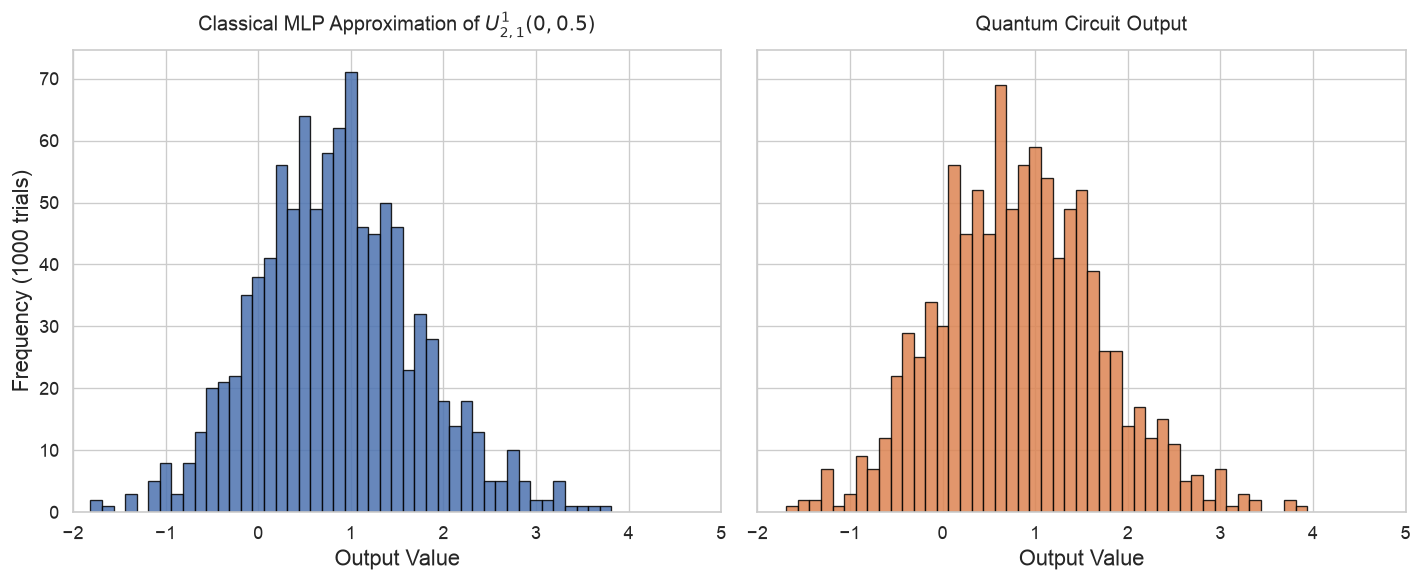

In [67]:
import seaborn as sns
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

q_counts = prob_profile_dict
c_trials = disc_trials

c_counts = Counter(c_trials)

q_x = sorted(list(q_counts.keys()))
q_y = [q_counts[k] for k in q_x]

c_x = sorted(list(c_counts.keys()))
c_y = [c_counts[k] for k in c_x]

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, dpi=120)

bin_width = 0.125

axes[0].bar(c_x, c_y, width=bin_width, color='#4C72B0', edgecolor='black', alpha=0.85)
axes[0].set_title(r"Classical MLP Approximation of $U^1_{2,1}(0, 0.5)$", fontsize=12, pad=12)
axes[0].set_xlabel("Output Value", fontsize=13)
axes[0].set_ylabel("Frequency (1000 trials)", fontsize=13)
axes[0].set_xlim(-2, 5)

axes[1].bar(q_x, q_y, width=bin_width, color='#DD8452', edgecolor='black', alpha=0.85)
axes[1].set_title(r"Quantum Circuit Output", fontsize=12, pad=12)
axes[1].set_xlabel("Output Value", fontsize=13)
axes[1].set_xlim(-2, 5)

plt.tight_layout()
plt.show()

